<a href="https://colab.research.google.com/github/jananirjanani09-cyber/janani_rmdj/blob/main/RNN_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

print("Libraries loaded successfully")
print("TensorFlow version:", tf.__version__)


Libraries loaded successfully
TensorFlow version: 2.21.0


In [5]:

corpus = [
    "artificial intelligence is transforming education",
    "artificial intelligence helps students learn",
    "deep learning is a branch of artificial intelligence",
    "deep learning uses neural networks",
    "neural networks learn patterns from data"
]

print("Total sentences:", len(corpus))

for sentence in corpus:
    print(sentence)


Total sentences: 5
artificial intelligence is transforming education
artificial intelligence helps students learn
deep learning is a branch of artificial intelligence
deep learning uses neural networks
neural networks learn patterns from data


In [6]:

tokenizer = Tokenizer()
tokenizer.fit_on_texts(corpus)

total_words = len(tokenizer.word_index) + 1

print("Vocabulary size:", total_words)
print("Word index:", tokenizer.word_index)


Vocabulary size: 20
Word index: {'artificial': 1, 'intelligence': 2, 'is': 3, 'learn': 4, 'deep': 5, 'learning': 6, 'neural': 7, 'networks': 8, 'transforming': 9, 'education': 10, 'helps': 11, 'students': 12, 'a': 13, 'branch': 14, 'of': 15, 'uses': 16, 'patterns': 17, 'from': 18, 'data': 19}


In [7]:

sequences = []

for sentence in corpus:
    token_ids = tokenizer.texts_to_sequences([sentence])[0]

    for i in range(1, len(token_ids)):
        sequences.append(token_ids[:i + 1])

max_len = max(len(seq) for seq in sequences)

padded = pad_sequences(
    sequences,
    maxlen=max_len,
    padding="pre"
)

X = padded[:, :-1]
y = padded[:, -1]

print("Total sequences:", len(sequences))
print("X shape:", X.shape)
print("y shape:", y.shape)


Total sequences: 24
X shape: (24, 7)
y shape: (24,)


In [8]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 19
Testing samples: 5


In [12]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

# Check previous step values
print("Total words:", total_words)
print("Input shape:", X_train.shape)

# Build model
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Embedding(
        input_dim=total_words,
        output_dim=32,
        mask_zero=True
    ),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()


Total words: 20
Input shape: (19, 7)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 7, 32)          │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,772 (104.58 KB)

 Trainable params: 26,772 (104.58 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=4,
    verbose=1
)

print("Training completed!")


Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step - accuracy: 0.0526 - loss: 3.0005 - val_accuracy: 0.0000e+00 - val_loss: 2.9957
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.1579 - loss: 2.9917 - val_accuracy: 0.0000e+00 - val_loss: 2.9982
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2105 - loss: 2.9850 - val_accuracy: 0.0000e+00 - val_loss: 3.0009
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.3158 - loss: 2.9783 - val_accuracy: 0.2000 - val_loss: 3.0038
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.3684 - loss: 2.9710 - val_accuracy: 0.2000 - val_loss: 3.0072
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3158 - loss: 2.9628 - val_accuracy: 0.2000 - val_loss: 3.0113
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3158 - loss: 2.9532 - val_accuracy: 0.2000 - val_loss: 3.0163
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.2632 - loss: 2.9415 - val_accuracy: 0.200

In [14]:

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Accuracy: {:.2f}%".format(test_accuracy * 100))
print("Test Loss: {:.4f}".format(test_loss))


Test Accuracy: 40.00%
Test Loss: 5.6344


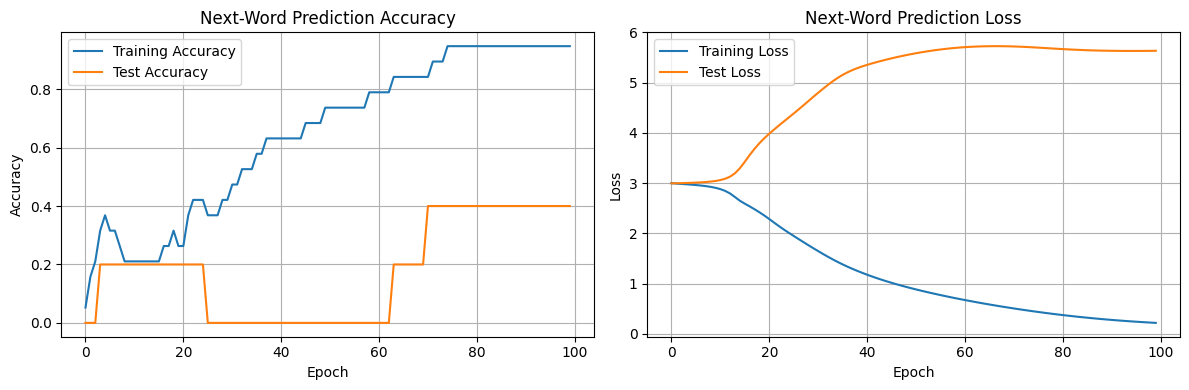

In [15]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Next-Word Prediction Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Next-Word Prediction Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [16]:

index_to_word = {
    index: word
    for word, index in tokenizer.word_index.items()
}

def predict_next_word(text):
    token_ids = tokenizer.texts_to_sequences([text])[0]

    if len(token_ids) == 0:
        return "Unknown"

    input_data = pad_sequences(
        [token_ids],
        maxlen=X_train.shape[1],
        padding="pre",
        truncating="pre"
    )

    probabilities = model.predict(input_data, verbose=0)[0]
    probabilities[0] = 0

    predicted_id = int(np.argmax(probabilities))

    return index_to_word.get(predicted_id, "Unknown")


print("Input: artificial intelligence")
print("Predicted next word:", predict_next_word(
    "artificial intelligence"
))


Input: artificial intelligence
Predicted next word: is


In [17]:

def generate_sentence(start_text, number_of_words=5):
    result = start_text

    for _ in range(number_of_words):
        next_word = predict_next_word(result)

        if next_word == "Unknown":
            break

        result += " " + next_word

    return result


print("Generated sentence:")
print(generate_sentence("artificial intelligence", 5))


Generated sentence:
artificial intelligence is transforming education education education
